In [ ]:
# Exécuter seulement dans Google Colab
!pip install myqlm -q -q

# Introduction
Ce TP est basé sur le framework `MyQLM`, dont le code et la documentation sont disponibles sur cette [page GitHub](https://myqlm.github.io/). L'objectif de la séance est d'implémenter la transformée de Fourier quantique (QFT), puis l'estimation de phase quantique (QPE) qui s'appuie sur elle.

In [ ]:
# Lire cette cellule, puis l'exécuter sans modification.
import numpy as np
import matplotlib.pyplot as plt
from qat.lang import QRoutine, H, PH, CNOT, RY, RZ, Z, X, CCNOT, Program, SWAP
from qat.qpus import get_default_qpu

qpu = get_default_qpu()

def display_result(circuit, nbshots=0, idx=None):
  '''
  Utilitary function to provide a nice display of the circuits.
  '''
  result = qpu.submit(circuit.to_job(nbshots=nbshots, qubits=idx)) # Objet de la classe Result
  if nbshots:
      tmp = {}
      for sample in result:
          state = sample.state
          if not state in tmp:
              tmp[state] = 0.
          tmp[sample.state] += sample.probability
      for state, proba in tmp.items():
          print(f"État {state}: probabilité {proba:.3f}")
  else:
      for sample in result:
          if sample.amplitude is None: # No amplitude when only a subset of qubits is measured
              print(f"État {sample.state}: probabilité {sample.probability:.3f}")
          else:
              print(f"État {sample.state}: probabilité {sample.probability:.3f}, amplitude {sample.amplitude:.3f}")

def get_result(circuit, idx=None):
    '''
    Return the states (as integers) and the amplitudes of a circuit (probabilities if idx is given).
    '''
    result = qpu.submit(circuit.to_job(nbshots=0, qubits=idx))
    states = []
    amplitudes = []
    for sample in result:
        states.append(sample.state.int)
        if idx:
            amplitudes.append(sample.probability)
        else:
            amplitudes.append(sample.amplitude)
    return np.array(states), np.array(amplitudes)

def encode(x):
    '''
    Return a routine encoding the vector x in the amplitudes of a quantum state.
    '''
    from qat.lang.models import KPTree

    return KPTree(x).get_routine(0)

## Transformée de Fourier quantique

La [transformée de Fourier quantique](https://fr.wikipedia.org/wiki/Transform%C3%A9e_de_Fourier_quantique) (QFT, *Quantum Fourier Transform*) est l'équivalent quantique de la transformée de Fourier discrète.

### Rappels : transformée de Fourier discrète

La [transformée de Fourier discrète](https://fr.wikipedia.org/wiki/Transformation_de_Fourier_discr%C3%A8te) (DFT) donne le spectre d'un signal échantillonné. Pour un signal $s$ de $N=2^n$ échantillons $s_0, \dots, s_{N-1}$, sa DFT $\hat{s}$ est définie par
$$
\hat{s}_k = \sum_{j=0}^{N-1} s_j e^{-2i \pi k \frac{j}{N}}.
$$

### Définition : transformée de Fourier quantique

La QFT agit comme la DFT (au signe de l'exponentielle près) sur un état quantique $\vert s \rangle = \sum_{i=0}^{N-1} s_i \vert i \rangle$ et renvoie $\vert \hat{s} \rangle = \sum_{i=0}^{N-1} \hat{s}_i \vert i \rangle$ avec
$$
\hat{s}_k = \frac{1}{\sqrt{N}} \sum_{j=0}^{N-1} s_j e^{2i \pi k \frac{j}{N}}.
$$
Elle s'écrit aussi comme un produit tensoriel de $n$ états à un qubit :
$$
QFT \vert x \rangle = \frac{1}{\sqrt{2^n}} \bigotimes_{k=n-1}^{0} \left( \vert 0 \rangle + e^{2i \pi x \frac{2^k}{2^n}} \vert 1 \rangle \right).
$$
On construit cet état qubit par qubit avec l'opérateur $U_k$ :
$$
U_k \vert x_0 \dots x_{n-1} \rangle = \vert x_0 \dots x_{k-1} \rangle \otimes \frac{1}{\sqrt{2}} \left( \vert 0 \rangle + e^{2i\pi x \frac{2^k}{2^n}} \vert 1 \rangle \right) \otimes \vert x_{k+1} \dots x_{n-1} \rangle.
$$
Pour cela, on place le qubit en superposition uniforme avec une porte $H$, puis on applique des phases contrôlées, comme l'illustre le GIF ci-dessous.



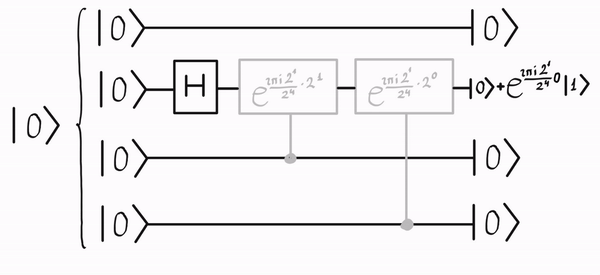

*source : [https://pennylane.ai/qml/demos/tutorial_qft]*


### Implémentation de la QFT

On commence par définir l'opérateur $U_k$ qui agit sur le $k$-ème qubit d'un état $x$ à $n$ qubits. La porte $PH(\varphi)$ applique la phase $e^{i\varphi}$ à l'état $\vert 1 \rangle$.

**Question 1.** Implémenter l'opérateur $U_k$ pour $n$ et $k$ quelconques.

In [ ]:
def U_k(n, k):
    # Routine creation
    rout = QRoutine()

    # <<< COMPLETE HERE >>>

    return rout

**Question 2.** Implémenter la `qft` en utilisant l'opérateur $U_k$.

In [ ]:
def qft(n):
    # Routine creation
    rout = QRoutine()

    # <<< COMPLETE HERE >>>

    return rout

La QFT est déjà implémentée dans `MyQLM` : on compare notre circuit au leur.

In [ ]:
n = 4
qft(n).display()

from qat.lang.AQASM.qftarith import QFT
QFT(n).display()

## Recherche de fréquence

### Signal sinusoïdal simple

La QFT permet de retrouver les fréquences qui composent un signal périodique. Le cas le plus simple est un signal sinusoïdal, qui n'a qu'une seule fréquence dans le domaine de Fourier. On teste la QFT sur le signal de fréquence $f$
$$
s(x) = \cos(2 \pi f x),
$$
échantillonné sur $N = 2^n$ points de $[0,1]$.

**Question 3.** Créer le vecteur du signal échantillonné $s$ et l'afficher avec matplotlib (`plt.plot`).

In [ ]:
n = 6
N = 2**n

f = 12

# <<< COMPLETE HERE >>>

On encode le vecteur $s$ dans un état quantique sur $n$ qubits avec la fonction `encode` (fournie en début de notebook). La fonction `get_result` donne les états et les amplitudes en sortie du circuit : on vérifie qu'on retrouve bien le signal $s$.

In [ ]:
circuit = encode(s)

states, amplitudes = get_result(circuit)
plt.plot(states/ 2**n, amplitudes)
plt.show()

On teste maintenant la QFT sur le signal encodé :
1. encoder $s$ ;
2. appliquer la QFT ;
3. inverser l'ordre des qubits du résultat (la QFT passe de la convention « bit de poids fort en premier » à « bit de poids faible en premier », et inversement).

**Question 4.** Appliquer la QFT sur le signal $s$ et observer le résultat avec `get_result` et matplotlib.

In [ ]:
rout = QRoutine()
qubits = rout.new_wires(n)

# <<< COMPLETE HERE >>>

On peut comparer la courbe obtenue à celle de la FFT de numpy.

In [ ]:
plt.plot(np.fft.fft(s))
plt.show()

### Modulation de signal sinusoïdal

Cas plus complexe : la modulation. Une sinusoïde de fréquence élevée $f_1$ (l'onde porteuse) interagit avec une sinusoïde de fréquence plus faible $f_2$ (le signal d'entrée). Le signal transmis est
$$
s(x) = \cos(2 \pi f_1 x) \cos(2 \pi f_2 x).
$$
Deux pics sont attendus dans le domaine de Fourier :
- un premier à $f_1 - f_2$ ;
- un second à $f_1 + f_2$.

**Question 5.** Créer le vecteur du signal échantillonné $s$ et l'afficher avec matplotlib (`plt.plot`).

In [ ]:
n = 8
N = 2**n

f1 = 40
f2 = 12

# <<< COMPLETE HERE >>>

**Question 6.** Appliquer la QFT sur le signal $s$ et observer le résultat avec `get_result` et matplotlib.

In [ ]:
rout = QRoutine()
qubits = rout.new_wires(n)

# <<< COMPLETE HERE >>>

On peut comparer la courbe obtenue à celle de la FFT de numpy.

In [ ]:
plt.plot(np.fft.fft(s))
plt.show()

## Estimation de phase quantique (QPE)

L'[algorithme d'estimation de phase quantique](https://fr.wikipedia.org/wiki/Algorithme_d%27estimation_de_phase_quantique) (QPE) estime les valeurs propres d'un opérateur unitaire $U$. Celles-ci sont sur le cercle unité (nombres complexes de module $1$) et s'identifient à leur phase, prise indifféremment dans $(-\pi, \pi)$ ou $(0, 2 \pi)$.

Si $\vert \psi \rangle$ est vecteur propre de $U$ de valeur propre $e^{2i \pi \theta}$, alors $U \vert \psi \rangle = e^{2i\pi \theta} \vert \psi \rangle$. L'objectif est de trouver $\theta$ : le circuit de la QPE doit réaliser
$$
QPE \vert \psi \rangle \vert 0 \rangle \longrightarrow \vert \psi \rangle \vert \theta \rangle.
$$
Le registre de phase compte $m$ qubits et $\vert \psi \rangle$ en compte $n$. L'algorithme se décompose en 3 étapes :
1. **Superposition** : un mur de portes $H$ crée une superposition uniforme sur toutes les valeurs possibles de $\theta$ ;
2. **Séquence contrôlée** : une séquence d'applications contrôlées de $U$ encode les phases ;
3. **QFT inverse** : elle extrait la valeur de $\theta$.

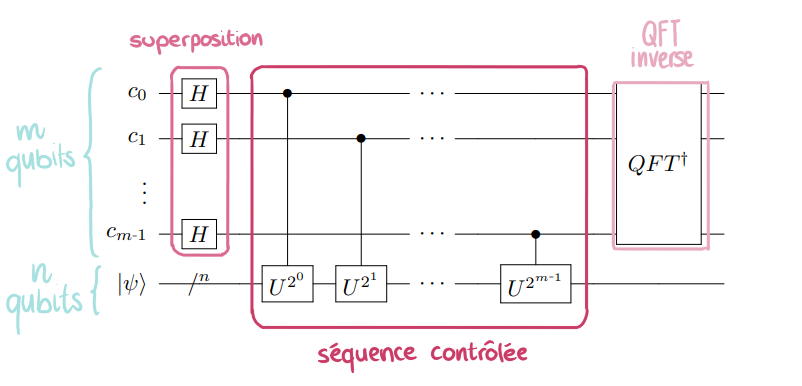

Une mesure du registre de phase donne alors $\theta$.

### Superposition
Un mur de portes $H$ sur le registre de phase produit
$$
\vert \psi \rangle \vert 0 \rangle \rightarrow \frac{1}{\sqrt{2^m}} \vert \psi \rangle \sum_{k=0}^{2^m-1} \vert k \rangle.
$$

### Séquence contrôlée
On intègre maintenant l'opérateur $U$. Pour une phase $\theta$ donnée, l'opération réalisée est
$$
\frac{1}{\sqrt{2^m}} \vert \psi \rangle \sum_{k=0}^{2^m-1} \vert k \rangle \rightarrow \frac{1}{\sqrt{2^m}} \vert \psi \rangle \sum_{k=0}^{2^m-1} e^{2i\pi\theta k} \vert k \rangle,
$$
qui correspond au circuit quantique suivant :

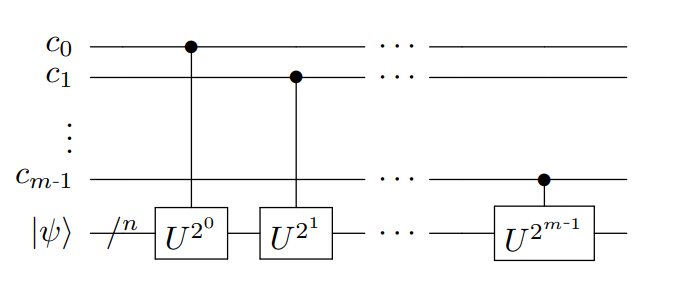

**Question 7.** Implémenter la routine correspondant à la séquence contrôlée.

In [ ]:
def controlled_sequence(U, n, m):
    # Routine creation
    rout = QRoutine()

    # <<< COMPLETE HERE >>>

    return rout

### QFT inverse

Dans $\frac{1}{\sqrt{2^m}} \vert \psi \rangle \sum_{k} e^{2i\pi\theta k} \vert k \rangle$, on reconnaît une expression dans le domaine des fréquences de Fourier. La QFT inverse permet d'en sortir et d'obtenir $\theta$ :
$$
\frac{1}{\sqrt{2^m}} \vert \psi \rangle \sum_{k=0}^{2^m-1} e^{2i\pi\theta k} \vert k \rangle \rightarrow \vert \psi \rangle \vert \theta \rangle.
$$

### Implémentation de la QPE

Avec la superposition, la séquence contrôlée et la QFT inverse, on peut implémenter la QPE selon l'image de circuit vue plus haut.

**Question 8.** Implémenter une routine quantique qui réalise la QPE pour un opérateur unitaire $U$.

In [ ]:
def qpe(n, m, U):
    # Routine creation
    rout = QRoutine()

    # <<< COMPLETE HERE >>>

    return rout

Pour récupérer toutes les valeurs propres de $U$, il faut appliquer la QPE plusieurs fois. Les fonctions suivantes simplifient le travail.

In [ ]:
# Quantum circuit to retrieve the eigenvalues
def get_eigenvalues(n, m, U):
    rout = QRoutine()
    reg_c = rout.new_wires(m)
    reg_d = rout.new_wires(n)

    # Uniform superposition on the vector |psi>
    for q in reg_d:
        H(q)

    qpe(n, m, U)(reg_c, reg_d)

    return rout

# Convert from the binary representation to the floating-point representation on (-1, 1)
def binary_to_double(nb_bits, val):
    half = (1 << (nb_bits - 1))
    def convert(val):
        return val / half if val <= half else val / half - 2
    return np.vectorize(convert)(val)

### Test de la QPE

On exprime ici les phases dans $(-\pi, \pi)$, donc $\theta \in (-1, 1)$. Cas d'usage simple : pour $\theta \in (-1, 1)$, la matrice à 1 qubit
$$
RZ(2 \pi \theta) = \begin{pmatrix} e^{-i \pi \theta} & 0 \\ 0 & e^{i \pi \theta} \end{pmatrix}
$$
a pour valeurs propres $\{ e^{i \pi \theta}, e^{-i \pi \theta}\}$. La QPE doit donc donner $(-\theta, \theta)$. On teste ici avec $\theta = 0.25$.

In [ ]:
# Theta in [-1., 1.]
theta = 0.25
# Creation of the unitary U
U1 = RZ(2 * np.pi * theta)
# Number of qubits of U
n = 1
# Number of qubits encoding the eigenvalues (-theta, theta)
m = 3

circuit = get_eigenvalues(n, m, U1)
states, probas = get_result(circuit, idx=[0,1,2])
states = binary_to_double(m, states)
plt.plot(states, probas, "o")
plt.grid()
plt.show()

**Question 9.** Expérimenter avec d'autres valeurs de $\theta$. Pourquoi le choix de $m$ est-il important pour obtenir une bonne estimation des valeurs propres ?

In [ ]:
# Theta in [-1., 1.]
theta = 0.25
# Creation of the unitary U
U1 = RZ(2 * np.pi * theta)
# Number of qubits of U
n = 1
# Number of qubits encoding the eigenvalues (-theta, theta)
m = 3

circuit = get_eigenvalues(n, m, U1)
states, probas = get_result(circuit, idx=[i for i in range(m)])
states = binary_to_double(m, states)
plt.plot(states, probas, "o")
plt.grid()
plt.show()

On essaie maintenant sur un opérateur agissant sur 2 qubits, dont le circuit est le suivant :

In [ ]:
def U2(theta1, theta2):
    rout = QRoutine()
    qubits = rout.new_wires(2)

    RZ(2 * np.pi * theta1)(qubits[0])
    RZ(2 * np.pi * theta2)(qubits[1])

    return rout

**Question 10.** Déterminer les valeurs propres de `U2` avec la QPE pour
- $\theta_1 = 0.25, \; \theta_2 = 0.125$
- $\theta_1 = 0.1875, \; \theta_2 = 0.125$

In [ ]:
# <<< COMPLETE HERE >>>

## Pour aller plus loin

L'[algorithme de Shor](https://fr.wikipedia.org/wiki/Algorithme_de_Shor) (Peter Shor, 1994) factorise un entier naturel $N$ en deux autres entiers, ce qui permet de casser de nombreux codes cryptographiques comme RSA. Il repose sur la QFT implémentée dans ce TP : quand $N$ ne se factorise pas trivialement avec des ressources classiques, l'ordinateur quantique prend en charge une partie du travail.

1. Prendre un nombre pseudo-aléatoire $a < N$.
2. Calculer $PGCD(a, N)$. Si $a$ et $N$ ne sont pas premiers entre eux, on a trouvé un facteur non trivial de $N$ et on s'arrête.
3. Utiliser un programme quantique reposant sur la QFT pour trouver la période $r$ de la fonction $f(x) = a^x \bmod N$.
4. À partir de $r$, déterminer un facteur de $N$. Si c'est impossible, retourner à l'étape 1.

En pratique, les ordinateurs quantiques actuels sont encore très loin d'être assez puissants et tolérants aux erreurs pour casser RSA.